In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte


MNIST est une base de données contenant :
60 000 images d'entraînement
10 000 images de test
chiffres manuscrits de 0 à 9

Chaque image :
- Noir et blanc
- Taille 28×28 pixels
- Une seule classe parmi 10 classes

Mon objectif est donc :

1) donner une image au modèle ----> le modèle doit prédire le chiffre présent sur l'image.

Input (28x28) -->Conv2D -->ReLU-->MaxPooling-->Flatten-->Layer connecte du reseau-->Output (10 classes)
c est ca l architecture que je vais adopter 

## Partie 1 : CNN sur MNIST

# Construire un CNN avec PyTorch

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader,Dataset
from sklearn.metrics import accuracy_score, f1_score
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [6]:
transform = transforms.ToTensor() #convertir les images en tenseurs

In [7]:
train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    transform=transform, # applique la transformation Totensor a chaque image du dataset 
    download=True
) # charger data de train : 60 000 images

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.60MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.86MB/s]


In [8]:
test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    transform=transform,
    download=True
) # charger data de test : 10 000 images

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
) # creer le dataloader pour le train : permet de fournir au modele les donnees sous forme des batches

In [12]:
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False # en conservant l ordre des images
) # creer le dataloader our le test

In [13]:
images, labels = next(iter(train_loader))

print("Forme des images :", images.shape)
print("Forme des labels :", labels.shape)
print("Premier label :", labels[0].item())

Forme des images : torch.Size([64, 1, 28, 28])
Forme des labels : torch.Size([64])
Premier label : 5


64 : nombre d'images dans le batch.



1 : nombre de canaux (noir et blanc).



28 : hauteur de chaque image.



28 : largeur de chaque image.

In [15]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # la 1ere couche de convolution
        self.conv1 = nn.Conv2d(
            in_channels=1,# image entree a un canal
            out_channels=32,# couche use 32 filtres differents
            kernel_size=3 # chaque filtre de taille 3 x 3 pixels
        ) 
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2,2)

        # 2eme couche de convolution 
        self.conv2 = nn.Conv2d(
            in_channels=32, # produit de la couche precedante
            out_channels=64,# 64 filtres differents
            kernel_size=3 # 3 × 3 pixels
        )
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(64*5*5, 128) # entree est de 1600 valeurs 64 x 5 x 5 
        self.fc2 = nn.Linear(128,10)

    def forward(self,x):
        # Extraction des caracteristiques
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x) # jusqua ici le reseau a juste extrait caracteristiques mais maintenat doit decider quel chiffre 
        x = x.view(-1,64*5*5)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)

        return x

In [16]:
# initialiser le modele
model = CNN().to(device)
criterion = nn.CrossEntropyLoss() # probleme de classification multiclass 

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4    # régularisation L2
)

In [17]:
def evaluate(model, loader):
    model.eval()                      # desactive le dropout
    total_loss, n = 0.0, 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0) # convertit le tenseur qui contient la perye en valeur numerique , la perte obtebue est la moyenne du batch 
            n += labels.size(0) # compter les images evaluees
            y_pred.extend(outputs.argmax(1).cpu().numpy())
            y_true.extend(labels.cpu().numpy())
    return total_loss / n, np.array(y_true), np.array(y_pred) # la perte moyenne par image , vrai labels, les predictions 


epochs = 10
history = {"train_loss": [], "test_loss": []} # conserve les pertes obtenues a chaque etape 
start_time = time.time()

for epoch in range(epochs):
    model.train()                     # reactive le dropout
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    test_loss, _, _ = evaluate(model, test_loader)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    print(f"Epoch {epoch+1}/{epochs} | train loss={train_loss:.4f} | test loss={test_loss:.4f}")

training_time = time.time() - start_time

Epoch 1/10 | train loss=0.2731 | test loss=0.0572
Epoch 2/10 | train loss=0.0996 | test loss=0.0389
Epoch 3/10 | train loss=0.0721 | test loss=0.0299
Epoch 4/10 | train loss=0.0605 | test loss=0.0351
Epoch 5/10 | train loss=0.0527 | test loss=0.0304
Epoch 6/10 | train loss=0.0456 | test loss=0.0270
Epoch 7/10 | train loss=0.0429 | test loss=0.0262
Epoch 8/10 | train loss=0.0379 | test loss=0.0224
Epoch 9/10 | train loss=0.0355 | test loss=0.0264
Epoch 10/10 | train loss=0.0315 | test loss=0.0233


In [18]:
test_loss, true_labels, predictions = evaluate(model, test_loader) # perte moyenne ,vrais chiffres, chiffres predits 

accuracy = accuracy_score(true_labels, predictions)
f1 = f1_score(true_labels, predictions, average='weighted')

print("Test loss     :", round(test_loss, 4))
print("Accuracy      :", round(accuracy, 4))
print("F1 Score      :", round(f1, 4))
print("Training time :", round(training_time, 1), "s")
print()
print(classification_report(true_labels, predictions, digits=4))

Test loss     : 0.0233
Accuracy      : 0.9917
F1 Score      : 0.9917
Training time : 97.9 s

              precision    recall  f1-score   support

           0     0.9899    0.9990    0.9944       980
           1     0.9895    0.9965    0.9930      1135
           2     0.9942    0.9913    0.9927      1032
           3     0.9911    0.9960    0.9936      1010
           4     0.9928    0.9898    0.9913       982
           5     0.9910    0.9888    0.9899       892
           6     0.9937    0.9875    0.9906       958
           7     0.9922    0.9883    0.9903      1028
           8     0.9959    0.9897    0.9928       974
           9     0.9871    0.9891    0.9881      1009

    accuracy                         0.9917     10000
   macro avg     0.9917    0.9916    0.9917     10000
weighted avg     0.9917    0.9917    0.9917     10000



precision : Fiabilité des prédictions pour une classe donnée.

recall : Capacité à retrouver les vrais exemples de cette classe.

f1-score : Compromis entre précision et rappel.

support : Nombre d'exemples réels de cette classe dans le test.

accuracy : proportion globale de prédictions correctes.
macro avg : moyenne des métriques des 10 classes, chaque classe ayant le même poids.
weighted avg : moyenne pondérée par le nombre d'exemples de chaque classe.

interpretation : 
les chiffres les plus difficiles : 
5 - 3 - 1

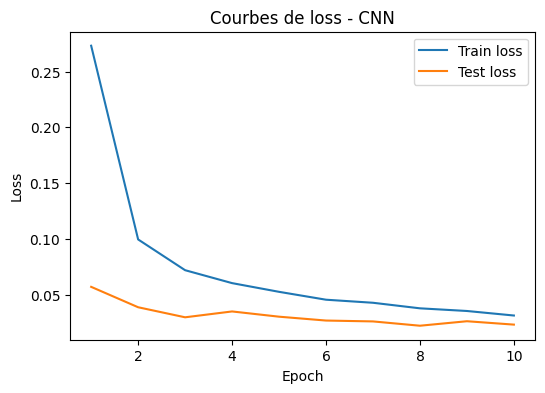

In [19]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs+1), history["train_loss"], label="Train loss")
plt.plot(range(1, epochs+1), history["test_loss"], label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Courbes de loss - CNN")
plt.legend()
plt.show()

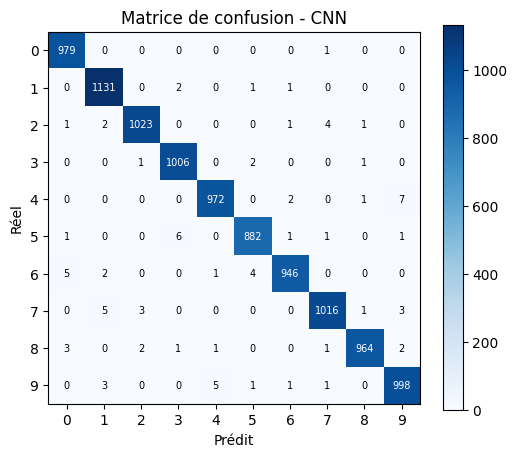

In [21]:
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title("Matrice de confusion - CNN")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max()/2 else "black")
plt.show()

# interpretation 
Le CNN composé de deux couches de convolution 3×3, d'un MaxPooling 2×2 et d'un dropout de 0,5 obtient d'excellentes performances sur MNIST avec une accuracy de 99,17 %, un F1-score de 0,9917 et une loss de test de 0,0233 après 10 epochs d'entraînement. Les métriques de précision, rappel et F1-score dépassent 98 % pour toutes les classes, montrant une reconnaissance très fiable des chiffres manuscrits. L'analyse de la matrice de confusion révèle que la majorité des prédictions se situent sur la diagonale principale, tandis que les rares erreurs concernent principalement des chiffres visuellement similaires, tels que 4 et 9, 5 et 3, ou encore 2 et 7. Ces résultats confirment la robustesse et l'efficacité du CNN pour la classification des chiffres du dataset MNIST.

# Faster R-CNN

Faster R-CNN doit faire deux choses :
1. Détecter où se trouve le chiffre dans l'image.
2. Classifier le chiffre, c'est-à-dire dire qu'il s'agit du chiffre 7.
   
-> Pour indiquer sa position, on dessine un rectangle autour du chiffre. Ce rectangle est appelé une boîte englobante

CNN ->> Prédiction : chiffre 7

Faster R-CNN ->> Prédiction : chiffre 7 + position du rectangle

Une boîte englobante est généralement représentée par quatre coordonnées :
\[
[x_{\min}, y_{\min}, x_{\max}, y_{\max}]
\]

- \(x_{\min}\) : bord gauche du rectangle.
- \(y_{\min}\) : bord supérieur.
- \(x_{\max}\) : bord droit.
- \(y_{\max}\) : bord inférieur.

L'idée est la suivante :
1. Charger une image MNIST.
2. Repérer les pixels qui correspondent à l'encre du chiffre, plutôt qu'au fond.
3. Trouver le pixel le plus à gauche, le plus à droite, le plus haut et le plus bas.
4. Utiliser ces quatre limites pour construire le rectangle.

### creer les boites englobantes

In [22]:
def get_boundring_box(image):
    
    # l image 
    pixels = image[0].numpy() # on recupere seulement le canal - devient une matrice de 28 L et 28 colonnes 

    # cherher les coordonnes des pixels 
    ys, xs = np.where(pixels  > 0.1) # ys correspond aux lignes et xs correspond aux colonnes 

    # si il ne trouve aucun pixel on return une boite couvrant toute image 
    if len(xs) == 0:
        return [0, 0, 28, 28]


    x_min = xs.min() # bord gauche
    y_min = ys.min()
    x_max = xs.max() + 1 # ajout de 1 pour que le dernier pixel soit inclus au niveau de la biote 
    y_max = ys.max() + 1

    return [x_min, y_min, x_max, y_max]

In [23]:
# on va verifier la boite
print(train_dataset[0]) 

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000

1er image est 5 -  Les pixels blancs ou gris du chiffre ont des valeurs proches de 1

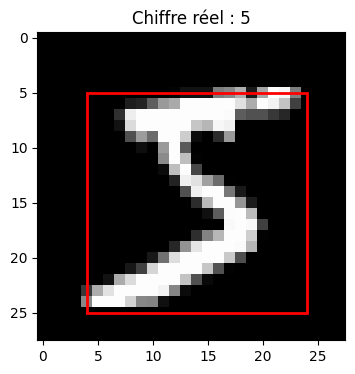

Boîte : [np.int64(4), np.int64(5), np.int64(24), np.int64(25)]


In [24]:
# recuperer 1er element du datset c-a-d la 1r image et son label comme ona remarquer que le tuple contient 
#(
 #image,
 #label
#)

image, label = train_dataset[0]
box = get_boundring_box(image)

x_min, y_min, x_max, y_max = box
plt.figure(figsize=(4, 4))
plt.imshow(image.squeeze(0), cmap="gray")

rect = plt.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

plt.gca().add_patch(rect)
plt.title(f"Chiffre réel : {label}")
plt.show()

print("Boîte :", box)

### on adapte MNIST a faster R-CNN
Faster R-CNN attend une image et une cible contenant au minimum les boîtes et les étiquettes des objets
la cible est comme ca : 

target ={

"boxes": ..., contient coordonnees du rectangle entourant l objet 

"labels": ... contient la classe de objet 

}

dans Faster R-CNN
0 = fond (background) cad aucun objet 

1 = chiffre 0

2 = chiffre 1

3 = chiffre 2

4 = chiffre 3

5 = chiffre 4

6 = chiffre 5

on va trasformer _ (image, label) ---> (image, target)

In [31]:

# creer new dataset compatible avec faster R-CNN
class MNISTDetection(Dataset):
    def __init__(self, mnist_dataset):
        self.dataset = mnist_dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, digit = self.dataset[index]

        box = get_boundring_box(image)
        # Faster R-CNN attend 3 cannaux RGB car use backbone ResNet50 qui est pre entrainer sur imafe RGB [3,h,w]
        image = image.repeat(3,1,1) # on va faire cannaux ×3 et qui vont etre identiques

        # creer target 
        target = {
            "boxes": torch.tensor(
                [box], dtype=torch.float32 # [] car faster attend une liste des objet puisque est concue pour plusieur objets 
                
            ),
            "labels": torch.tensor(
                [digit +1], dtype=torch.int64
            ),
            "image_id": torch.tensor([index]),# num identifiant de image 
            "area": torch.tensor(
                [(box[2] - box[0]) * (box[3] - box[1])], dtype=torch.float32 # calcul surface de la boite 
            ),
            "iscrowd": torch.tensor([0], dtype=torch.int64) # indique est ce que c est un grp de personnes 
            
        }
        return image, target

In [32]:
# creation des datasets pour faster r-cnn
train_detection = MNISTDetection(train_dataset)
test_detection = MNISTDetection(test_dataset)

# on doit avoir fct pour resorganiser data du batch on veu avoir images = [image1, image2, ...] targets = [target1, target2, ...]

def collate_fn(batch):
    return tuple(zip(*batch)) # * pour decomposer la liste et zip prend le 1er elem de chaque tuple puis le 2eme

train_loader = DataLoader(
    train_detection,
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn # pour use la fct definie pour construire les batches au lieu de use celle par defaut 
)

test_loader = DataLoader(
    test_detection,
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

### construire le Faster R-CNN

In [33]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)


In [34]:
# charger les poids preentraines
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
# creer le model 
model = fasterrcnn_resnet50_fpn(
    weights=weights
)

# nbre de classe 11 le fond et 10 chiffres 
nbre_classes = 11

# pour savoir combien de caracteristiques arrivent a la couche finale 
in_features = model.roi_heads.box_predictor.cls_score.in_features

from torchvision.models.detection.faster_rcnn import FastRCNNPredictor # new classifer pour  remplacer la couche finale

# remplacer tete de classification car avant il connait un autre nbre de classes donc on doit remplacer ancienne tete 
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    nbre_classes
)

# le mettre au gpu 
model.to(device)
print("Faster R-CNN prêt sur :", device)



Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 240MB/s] 


Faster R-CNN prêt sur : cuda


In [35]:
# on doit definir l optimizer 
# selectionner les params a entrainer 
params = [
    p for p in model.parameters() #  model.parameters()  return tous les poids du model 
    # on verifier cet attribut requires_grad  ( qui val true ou false )de  chaque poids qui sert a dire si on veux entrainer ce poids ou non on veut pas le modifier
    # donc ici on va prendre juste les params qui doivent etre entraines 
    if p.requires_grad  
]

optimizer = torch.optim.SGD(
    params,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005 # regularisation L2
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3, # Tous les 3 epochs on modifier le lr
    gamma=0.1 # le new va etre l ancien * gamma 
) # on reduit auto le lr pendant entrainement 


### Entrainer le model 

In [ ]:
epochs = 3
history = [] # historique des pertes 
start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, targets in train_loader:
        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in target.items()}
            for target in targets
        ]

        loss_dict = model(images, targets)

        loss = sum(loss for loss in loss_dict.values()) # somme de toutes les losses

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    lr_scheduler.step()

    epoch_loss = running_loss / len(train_loader)
    history.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"| train loss = {epoch_loss:.4f}"
    )

training_time = time.time() - start_time

print(f"Temps d'entraînement : {training_time:.1f} s")

In [39]:
print("Nombre d'images :", len(train_loader.dataset))
print("Nombre de lots par époque :", len(train_loader))
print("Taille des lots :", train_loader.batch_size)

Nombre d'images : 60000
Nombre de lots par époque : 7500
Taille des lots : 8


Remarque : Afin de réduire le temps d'exécution et de respecter les limites
de durée et de quota de Kaggle, l'entraînement est limité à 500 batches
par époque, au lieu de traiter l'intégralité du jeu de données.
Avec une taille de batch de 8, environ 4 000 images sont traitées par époque.
Un checkpoint du modèle est sauvegardé à la fin de chaque époque
afin de conserver les paramètres appris et de pouvoir reprendre l'entraînement.

In [40]:

import time
import torch
from tqdm.auto import tqdm

epochs = 3
max_batches = 500
history = []

start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    num_batches = min(max_batches, len(train_loader))

    progress = tqdm(
        enumerate(train_loader),
        total=num_batches,
        desc=f"Epoch {epoch + 1}/{epochs}"
    )

    for step, (images, targets) in progress:
        if step >= max_batches:
            break

        images = [img.to(device) for img in images]
        targets = [
            {k: v.to(device) for k, v in target.items()}
            for target in targets
        ]

        loss_dict = model(images, targets)
        loss = sum(loss_value for loss_value in loss_dict.values())

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    lr_scheduler.step()

    epoch_loss = running_loss / num_batches
    history.append(epoch_loss)

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": lr_scheduler.state_dict(),
        "history": history
    }, "/kaggle/working/fasterrcnn_checkpoint.pth")

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"| loss = {epoch_loss:.4f}",
        flush=True
    )

print(f"Temps total : {time.time() - start_time:.1f} s")


Epoch 1/3:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1/3 | loss = 0.0395


Epoch 2/3:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 2/3 | loss = 0.0357


Epoch 3/3:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 3/3 | loss = 0.0298
Temps total : 2554.4 s


In [41]:
import os

checkpoint_path = "/kaggle/working/fasterrcnn_checkpoint.pth"

print("Checkpoint disponible :", os.path.exists(checkpoint_path))

Checkpoint disponible : True


In [42]:
from sklearn.metrics import f1_score, classification_report

training_time = 2554.4  # Temps obtenu pendant l'entraînement, en secondes

### Evaluer les predictions 

In [44]:

from tqdm.auto import tqdm
from sklearn.metrics import f1_score, classification_report

model.eval()

true_labels = []
predictions = []
total_correct = 0
total_images = 0

max_test_batches = 500
num_batches = min(max_test_batches, len(test_loader))

with torch.no_grad():
    for step, (images, targets) in enumerate(
        tqdm(test_loader, total=num_batches, desc="Évaluation Faster R-CNN")
    ):
        if step >= max_test_batches:
            break

        images = [img.to(device) for img in images]
        outputs = model(images)

        for output, target in zip(outputs, targets):
            true_digit = int(target["labels"][0].item()) - 1

            if len(output["scores"]) > 0:
                best_idx = output["scores"].argmax().item()
                pred_digit = int(output["labels"][best_idx].item()) - 1
            else:
                pred_digit = -1

            true_labels.append(true_digit)
            predictions.append(pred_digit)

            total_images += 1
            total_correct += int(pred_digit == true_digit)

print("Évaluation terminée.")
print("Nombre d'images évaluées :", total_images)

accuracy = total_correct / total_images if total_images else 0

f1 = f1_score(
    true_labels,
    predictions,
    labels=list(range(10)),
    average="weighted",
    zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("F1-score pondéré :", round(f1, 4))
print("Training time :", round(training_time, 1), "s")

print(classification_report(
    true_labels,
    predictions,
    labels=list(range(10)),
    digits=4,
    zero_division=0
))


Évaluation Faster R-CNN:   0%|          | 0/500 [00:00<?, ?it/s]

Évaluation terminée.
Nombre d'images évaluées : 4000
Accuracy : 0.966
F1-score pondéré : 0.9661
Training time : 2554.4 s
              precision    recall  f1-score   support

           0     0.9784    0.9784    0.9784       370
           1     0.9843    0.9756    0.9799       450
           2     0.9591    0.9545    0.9568       418
           3     0.9804    0.9804    0.9804       408
           4     0.9196    0.9856    0.9515       418
           5     0.9972    0.9516    0.9739       372
           6     0.9487    0.9788    0.9635       378
           7     0.9586    0.9586    0.9586       411
           8     0.9782    0.9349    0.9561       384
           9     0.9640    0.9591    0.9615       391

    accuracy                         0.9660      4000
   macro avg     0.9669    0.9658    0.9661      4000
weighted avg     0.9666    0.9660    0.9661      4000



Accuracy de 96,60 % : le modèle a correctement identifié 3 864 chiffres sur les 4 000 images évaluées.



F1-score de 0,9661 : le score est élevé, ce qui indique un bon équilibre global entre précision et rappel pour les différentes classes.



Meilleure classe : le chiffre 5 possède une précision de 99,72 %, tandis que le chiffre 4 possède un rappel de 98,56 %.



Classe à surveiller : le chiffre 8 a le rappel le plus faible, à 93,49 %. Le modèle manque donc davantage de chiffres 8 que des autres chiffres, selon cette évaluation.

# ce code c etait pour evaluation mais il est tres lourd et il va perndre bcp de temps et consomme bcp de ressources 

model.eval()

true_labels = []
predictions = []
total_correct = 0
total_images = 0

with torch.no_grad():
    for images, targets in test_loader:
        images = [img.to(device) for img in images]

        outputs = model(images) # on est dans phase de test  on ne passe pas target 

        for output, target in zip(outputs, targets):
            true_digit = int(target["labels"][0].item()) - 1

            # Classe predite avec le score maximal
            if len(output["scores"]) > 0: # car parfois va etre vide cad ne detecte rien 
                best_idx = output["scores"].argmax().item()
                pred_class = int(output["labels"][best_idx].item())
                pred_digit = pred_class - 1
            else:
                pred_digit = -1

            true_labels.append(true_digit)
            predictions.append(pred_digit)

            total_images += 1
            total_correct += (pred_digit == true_digit)

accuracy = total_correct / total_images
f1 = f1_score(
    true_labels,
    predictions,
    labels=list(range(10)),
    average="weighted",
    zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("F1-score :", round(f1, 4))
print("Training time :", round(training_time, 1), "s")
print(
    classification_report(
        true_labels,
        predictions,
        labels=list(range(10)),
        digits=4,
        zero_division=0
    )
)

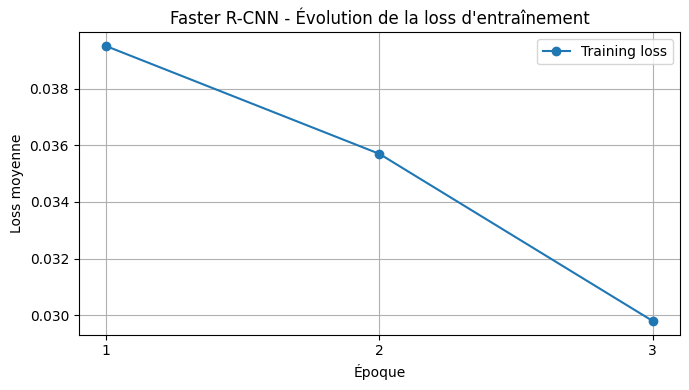

Époque 1 : loss = 0.0395
Époque 2 : loss = 0.0357
Époque 3 : loss = 0.0298


In [45]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    range(1, len(history) + 1),
    history,
    marker="o",
    label="Training loss"
)

plt.xlabel("Époque")
plt.ylabel("Loss moyenne")
plt.title("Faster R-CNN - Évolution de la loss d'entraînement")
plt.xticks(range(1, len(history) + 1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

for epoch, loss in enumerate(history, start=1):
    print(f"Époque {epoch} : loss = {loss:.4f}")


In [46]:
import pandas as pd

fasterrcnn_results = pd.DataFrame([{
    "Model": "Faster R-CNN",
    "Accuracy": accuracy,
    "F1-score": f1,
    "Training loss (final epoch)": history[-1],
    "Training time (s)": training_time,
    "Test images": total_images
}])

display(fasterrcnn_results)

,Model,Accuracy,F1-score,Training loss (final epoch),Training time (s),Test images
0,Faster R-CNN,0.966,0.966057,0.029805,2554.4,4000


# VGG16 and AlexNet

In [47]:
import os
import time
import copy
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import accuracy_score, f1_score, classification_report

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# GPU si disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

# Dossier des résultats
os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

# Paramètres
BATCH_SIZE = 32
EPOCHS = 3
LEARNING_RATE = 1e-4

# Prétraitement des images MNIST
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Télécharger et charger MNIST
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Images d'entraînement :", len(train_dataset))
print("Images de test :", len(test_dataset))

Device utilisé : cuda
Images d'entraînement : 60000
Images de test : 10000


In [48]:
def create_model(model_name):
    """
    Charge un modèle preentraine et adapte
    pour la classification de 10 chiffres.
    """

    if model_name == "AlexNet":
        model = models.alexnet(
            weights=models.AlexNet_Weights.DEFAULT
        )

        # Geler toutes les couches convolutionnelles
        for param in model.features.parameters():
            param.requires_grad = False

        # Débloquer la dernière couche convolutionnelle
        for param in model.features[-1].parameters():
            param.requires_grad = True

        # Remplacer la dernière couche de classification
        in_features = model.classifier[6].in_features
        model.classifier[6] = nn.Linear(in_features, 10)

    elif model_name == "VGG16":
        model = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )

        # Geler les couches convolutionnelles
        for param in model.features.parameters():
            param.requires_grad = False

        # Débloquer le dernier bloc convolutionnel
        for param in model.features[24:].parameters():
            param.requires_grad = True

        # Remplacer la dernière couche de classification
        in_features = model.classifier[6].in_features
        model.classifier[6] = nn.Linear(in_features, 10)

    else:
        raise ValueError("Modele inconnu")

    return model.to(device)


# Créer les modèles
alexnet = create_model("AlexNet")
vgg16 = create_model("VGG16")

print("AlexNet et VGG16 sont prêts.")

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:00<00:00, 245MB/s] 


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 226MB/s]  


AlexNet et VGG16 sont prêts.


### Entrainer & evaluer & sauvgarder les resultats 

In [49]:

def train_and_evaluate(model, model_name, epochs=3, max_batches=100):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE
    )

    history = []
    start_time = time.time()
    best_train_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())

    # ENTRAÎNEMENT
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total_train = 0

        for batch_idx, (images, labels) in enumerate(train_loader):

            # Limiter le nombre de batches
            if batch_idx >= max_batches:
                break

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total_train += images.size(0)

        epoch_loss = running_loss / total_train
        history.append(epoch_loss)

        print(
            f"{model_name} | Époque {epoch + 1}/{epochs} "
            f"| Batches : {min(batch_idx + 1, max_batches)} "
            f"| Images : {total_train} "
            f"| Loss : {epoch_loss:.4f}"
        )

        if epoch_loss < best_train_loss:
            best_train_loss = epoch_loss
            best_state = copy.deepcopy(model.state_dict())

    training_time = time.time() - start_time

    model.load_state_dict(best_state)

    # ÉVALUATION : limiter aussi les batches de test
    model.eval()
    test_loss_sum = 0.0
    total_test = 0
    all_labels = []
    all_predictions = []

    max_test_batches = 100

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(test_loader):

            if batch_idx >= max_test_batches:
                break

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss_sum += loss.item() * images.size(0)
            total_test += images.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    test_loss = test_loss_sum / total_test
    accuracy = accuracy_score(all_labels, all_predictions)
    f1_weighted = f1_score(
        all_labels,
        all_predictions,
        average="weighted"
    )

    print(f"\n===== Résultats : {model_name} =====")
    print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f} %)")
    print(f"F1-score : {f1_weighted:.4f}")
    print(f"Test loss : {test_loss:.4f}")
    print(f"Temps d'entraînement : {training_time:.2f} secondes")
    print(f"Images de test évaluées : {total_test}")

    print("\nRapport par classe :")
    print(classification_report(
        all_labels,
        all_predictions,
        labels=list(range(10)),
        zero_division=0
    ))

    # SAUVEGARDER LE MODÈLE
    os.makedirs("checkpoints", exist_ok=True)
    os.makedirs("results", exist_ok=True)

    torch.save(
        model.state_dict(),
        f"checkpoints/{model_name.lower()}_mnist.pth"
    )

    # COURBE DE LOSS
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, epochs + 1), history, marker="o")
    plt.xlabel("Époque")
    plt.ylabel("Loss moyenne d'entraînement")
    plt.title(f"{model_name} - Évolution de la loss")
    plt.xticks(range(1, epochs + 1))
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"results/{model_name.lower()}_loss.png")
    plt.show()

    return {
        "Modèle": model_name,
        "Accuracy (%)": accuracy * 100,
        "F1-score pondéré": f1_weighted,
        "Test loss": test_loss,
        "Temps entraînement (s)": training_time,
        "Images entraînement par époque": total_train,
        "Images de test": total_test,
        "Loss par époque": history
    }


### Fine-tuning d'AlexNet

AlexNet | Époque 1/3 | Batches : 100 | Images : 3200 | Loss : 0.5664
AlexNet | Époque 2/3 | Batches : 100 | Images : 3200 | Loss : 0.1438
AlexNet | Époque 3/3 | Batches : 100 | Images : 3200 | Loss : 0.1382

===== Résultats : AlexNet =====
Accuracy : 0.9741 (97.41 %)
F1-score : 0.9741
Test loss : 0.0873
Temps d'entraînement : 11.48 secondes
Images de test évaluées : 3200

Rapport par classe :
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       287
           1       0.99      0.98      0.99       360
           2       0.93      0.99      0.96       333
           3       0.96      0.99      0.97       339
           4       0.98      0.99      0.99       339
           5       0.98      0.96      0.97       301
           6       1.00      0.94      0.97       296
           7       0.99      0.96      0.97       331
           8       0.98      0.98      0.98       304
           9       0.98      0.96      0.97       310

    accu

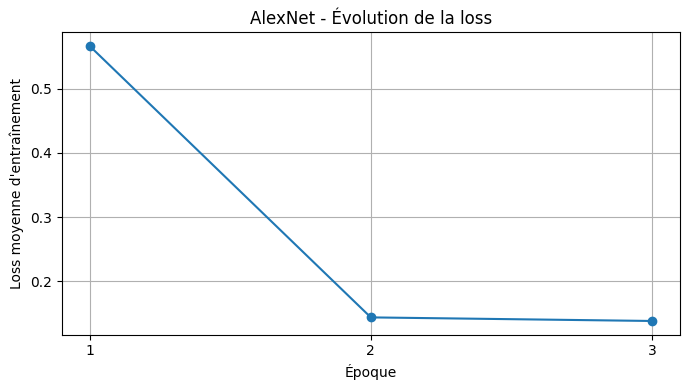

AlexNet terminé et sauvegardé.


In [50]:
# Fine-tuning d'AlexNet
alexnet_results = train_and_evaluate(
    model=alexnet,
    model_name="AlexNet",
    epochs=3,
    max_batches=100
)

# Enregistrer les résultats
with open("results/alexnet_results.json", "w") as f:
    json.dump(alexnet_results, f, indent=4)

print("AlexNet terminé et sauvegardé.")

### Fine-tuning de VGG16

VGG16 | Époque 1/3 | Batches : 100 | Images : 3200 | Loss : 0.4100
VGG16 | Époque 2/3 | Batches : 100 | Images : 3200 | Loss : 0.1067
VGG16 | Époque 3/3 | Batches : 100 | Images : 3200 | Loss : 0.0743

===== Résultats : VGG16 =====
Accuracy : 0.9772 (97.72 %)
F1-score : 0.9772
Test loss : 0.0683
Temps d'entraînement : 64.68 secondes
Images de test évaluées : 3200

Rapport par classe :
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       287
           1       0.98      0.99      0.99       360
           2       0.96      0.98      0.97       333
           3       0.99      0.98      0.98       339
           4       0.97      0.96      0.97       339
           5       0.97      0.99      0.98       301
           6       1.00      0.96      0.98       296
           7       0.98      0.97      0.97       331
           8       1.00      0.97      0.98       304
           9       0.96      0.98      0.97       310

    accuracy    

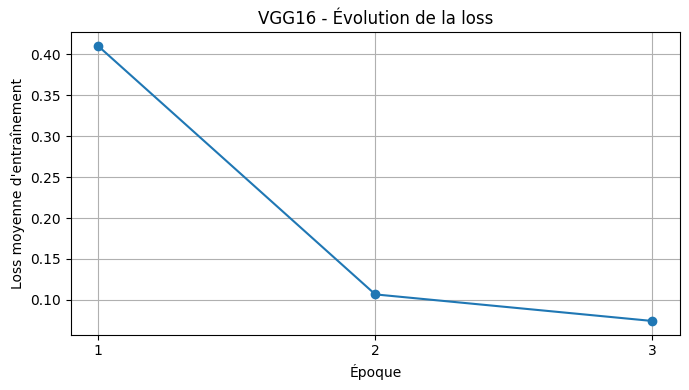

VGG16 terminé et sauvegardé.


In [53]:
import gc
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

vgg16 = create_model("VGG16")

vgg16_results = train_and_evaluate(
    model=vgg16,
    model_name="VGG16",
    epochs=3,
    max_batches=100
)

# Enregistrer les résultats
with open("results/vgg16_results.json", "w") as f:
    json.dump(vgg16_results, f, indent=4)

print("VGG16 terminé et sauvegardé.")

### le tableau comparatif des cinq modèles

In [54]:
# Résultats déjà obtenus lors de tes expériences.
# Les valeurs d'AlexNet et de VGG16 seront ajoutées après entraînement.

results = [
    {
        "Modèle": "CNN",
        "Accuracy (%)": 99.17,
        "F1-score pondéré": 0.9917,
        "Test loss": 0.0233,
        "Temps entraînement (s)": 97.9,
        "Images de test": 10000
    },
    {
        "Modèle": "ViT",
        "Accuracy (%)": 86.41,
        "F1-score pondéré": 0.8627,
        "Test loss": 0.4141,
        "Temps entraînement (s)": 53.8,
        "Images de test": 10000
    },
    {
        "Modèle": "Faster R-CNN",
        "Accuracy (%)": 96.60,
        "F1-score pondéré": 0.9661,
        "Test loss": np.nan,  # Loss de test non calculée
        "Temps entraînement (s)": 2554.4,
        "Images de test": 4000
    },
    {
        "Modèle": "AlexNet",
        "Accuracy (%)": alexnet_results["Accuracy (%)"],
        "F1-score pondéré": alexnet_results["F1-score pondéré"],
        "Test loss": alexnet_results["Test loss"],
        "Temps entraînement (s)": alexnet_results["Temps entraînement (s)"],
        "Images de test": alexnet_results["Images de test"]
    },
    {
        "Modèle": "VGG16",
        "Accuracy (%)": vgg16_results["Accuracy (%)"],
        "F1-score pondéré": vgg16_results["F1-score pondéré"],
        "Test loss": vgg16_results["Test loss"],
        "Temps entraînement (s)": vgg16_results["Temps entraînement (s)"],
        "Images de test": vgg16_results["Images de test"]
    }
]

df = pd.DataFrame(results)

# Afficher le tableau
display(df.round(4))

# Exporter les résultats au format CSV
df.to_csv("results/comparaison_modeles.csv", index=False)

# Exporter également au format Excel
df.to_excel("results/comparaison_modeles.xlsx", index=False)

print("Tableau enregistré dans results/")

,Modèle,Accuracy (%),F1-score pondéré,Test loss,Temps entraînement (s),Images de test
0,CNN,99.1700,0.9917,0.0233,97.9000,10000
1,ViT,86.4100,0.8627,0.4141,53.8000,10000
2,Faster R-CNN,96.6000,0.9661,NaN,2554.4000,4000
3,AlexNet,97.4062,0.9741,0.0873,11.4782,3200
4,VGG16,97.7188,0.9772,0.0683,64.6809,3200


Tableau enregistré dans results/


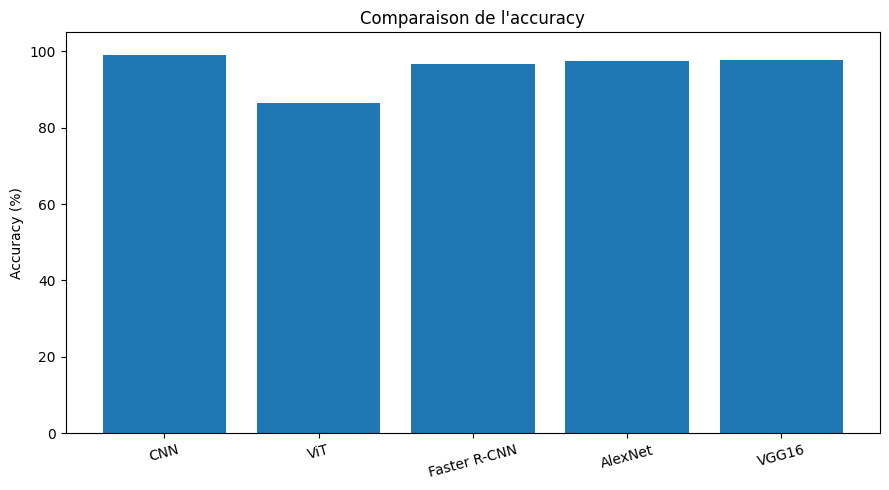

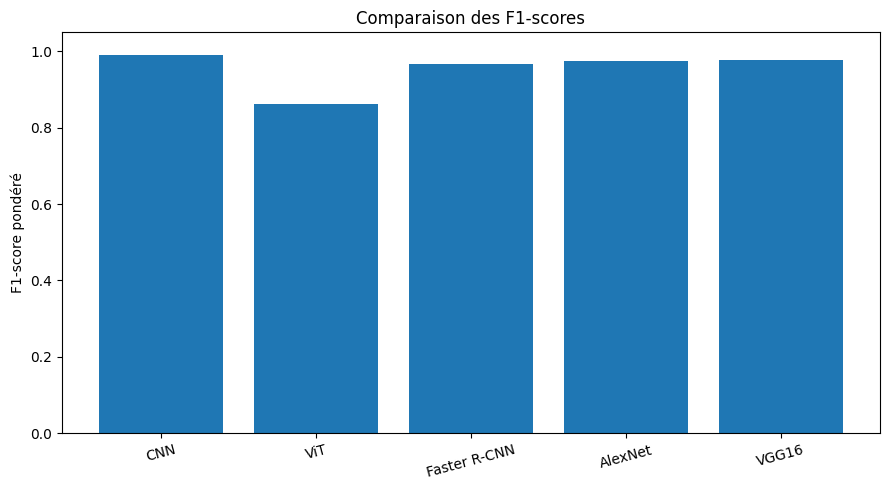

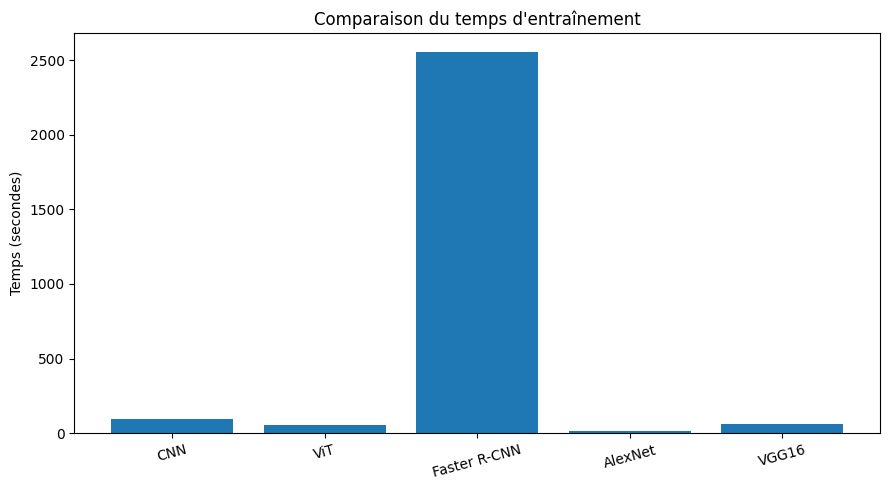

Tableaux et graphiques enregistrés dans le dossier results.


,Modèle,Accuracy (%),F1-score pondéré,Test loss,Temps entraînement (s),Images de test
0,CNN,99.1700,0.9917,0.0233,97.9000,10000
1,ViT,86.4100,0.8627,0.4141,53.8000,10000
2,Faster R-CNN,96.6000,0.9661,NaN,2554.4000,4000
3,AlexNet,97.4062,0.9741,0.0873,11.4782,3200
4,VGG16,97.7188,0.9772,0.0683,64.6809,3200


In [55]:

import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

df = pd.DataFrame({
    "Modèle": ["CNN", "ViT", "Faster R-CNN", "AlexNet", "VGG16"],
    "Accuracy (%)": [99.17, 86.41, 96.60, 97.4062, 97.7188],
    "F1-score pondéré": [0.9917, 0.8627, 0.9661, 0.9741, 0.9772],
    "Test loss": [0.0233, 0.4141, float("nan"), 0.0873, 0.0683],
    "Temps entraînement (s)": [97.9, 53.8, 2554.4, 11.4782, 64.6809],
    "Images de test": [10000, 10000, 4000, 3200, 3200]
})

# Enregistrer le tableau
df.to_csv("results/comparaison_modeles.csv", index=False)
df.to_excel("results/comparaison_modeles.xlsx", index=False)

# 1. Accuracy
plt.figure(figsize=(9, 5))
plt.bar(df["Modèle"], df["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Comparaison de l'accuracy")
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("results/comparaison_accuracy.png", dpi=300)
plt.show()

# 2. F1-score
plt.figure(figsize=(9, 5))
plt.bar(df["Modèle"], df["F1-score pondéré"])
plt.ylabel("F1-score pondéré")
plt.title("Comparaison des F1-scores")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("results/comparaison_f1.png", dpi=300)
plt.show()

# 3. Temps d'entraînement
plt.figure(figsize=(9, 5))
plt.bar(df["Modèle"], df["Temps entraînement (s)"])
plt.ylabel("Temps (secondes)")
plt.title("Comparaison du temps d'entraînement")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("results/comparaison_temps.png", dpi=300)
plt.show()

print("Tableaux et graphiques enregistrés dans le dossier results.")
display(df)


1. Conclusion 
Les résultats expérimentaux montrent que le choix de l'architecture du réseau de neurones influence considérablement les performances de classification des chiffres manuscrits sur le jeu de données MNIST.

Parmi les cinq modèles étudiés, le CNN obtient les meilleures performances, avec une accuracy de 99,17 %, un F1-score pondéré de 0,9917 et une test loss de 0,0233. Ces résultats montrent que les réseaux de neurones convolutifs sont particulièrement efficaces pour la reconnaissance des chiffres manuscrits.

VGG16 et AlexNet obtiennent également de bons résultats, avec des accuracies respectives de 97,72 % et 97,41 %. VGG16 est légèrement plus performant qu'AlexNet, mais son temps d'entraînement est plus élevé. Le modèle ViT obtient une accuracy de 86,41 %, la plus faible des cinq modèles. Enfin, Faster R-CNN atteint une accuracy de 96,60 %, mais son temps d'entraînement est nettement plus long, avec environ 42 minutes et 34 secondes.

En conclusion, le CNN offre le meilleur compromis entre précision de classification et coût de calcul dans cette expérience. Toutefois, il faut interpréter ces résultats avec prudence, car tous les modèles n'ont pas été évalués sur le même nombre d'images de test.


2. ViT — Question 2 : 
   
Dans la deuxième partie, nous avons évalué le modèle Vision Transformer (ViT) sur le jeu de données MNIST. Le modèle a obtenu une accuracy de 86,41 %, un F1-score pondéré de 0,8627 et une test loss de 0,4141. Son temps d'entraînement était de 53,8 secondes.

Ces résultats montrent que ViT est moins performant que le CNN développé dans la première partie. En effet, le CNN a obtenu une accuracy de 99,17 %, un F1-score pondéré de 0,9917 et une test loss de 0,0233. Il surpasse donc ViT en termes de précision de classification et de perte sur les données de test.

Cette différence peut s'expliquer par les caractéristiques des deux architectures. Les CNN sont particulièrement adaptés au traitement des images, car leurs couches convolutives permettent d'extraire des caractéristiques locales, comme les contours, les courbes et les formes des chiffres. En revanche, les Vision Transformers utilisent des mécanismes d'attention pour apprendre les relations entre différentes parties de l'image. Leurs performances peuvent dépendre fortement de l'architecture choisie, du prétraitement, de la stratégie d'entraînement et de la quantité de données disponibles.

Concernant le temps d'entraînement, ViT a nécessité 53,8 secondes, contre 97,9 secondes pour le CNN. Il a donc été plus rapide à entraîner dans cette expérience, mais ses performances de classification étaient nettement inférieures.

En conclusion, le CNN est plus performant que ViT pour la classification des chiffres manuscrits dans les conditions expérimentales utilisées. Cependant, pour garantir une comparaison rigoureuse, il est important de conserver les mêmes données de test et de contrôler les paramètres d'entraînement des deux modèles.

### Synythese 
Apprentissage de la conception et de l'entraînement d'un réseau de neurones convolutif (CNN) sur le dataset MNIST.



Découverte et expérimentation de différentes architectures : CNN, Vision Transformer (ViT), Faster R-CNN, AlexNet et VGG16.



Apprentissage du prétraitement des images pour les adapter aux exigences des différents modèles.



Découverte du fine-tuning permettant d'adapter des modèles préentraînés à une nouvelle tâche de classification.



Évaluation des modèles à l'aide de métriques telles que l'accuracy, la précision, le rappel, le F1-score et la loss.



Analyse des résultats à travers les courbes d'apprentissage et la matrice de confusion.



Comparaison des performances des architectures en termes de précision de classification et de temps d'entraînement.



Constatation que le CNN a obtenu la meilleure accuracy dans nos expériences, avec 99,17 %, tandis que Faster R-CNN a nécessité le temps d'entraînement le plus long.



Développement de compétences pratiques avec Python, PyTorch, TorchVision, Matplotlib et Scikit-learn.